# Customer value, segmentation and repeat purchase prediction for an online retailer

**Question.** Which customers drive revenue, how do they group into segments a marketing team can act on, and which customers are likely to buy again in the next 90 days?

**Why it matters.** For most retailers a small share of customers produces most of the revenue, and winning a new customer costs several times more than keeping an existing one. A retailer that knows who is about to lapse and who is about to buy can spend its marketing budget where it changes the outcome, instead of mailing everyone.

**Data.** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) from the UCI Machine Learning Repository: every transaction of a real UK-based online gift retailer between December 2009 and December 2011, just over one million invoice lines. Many of its customers are wholesalers.

**What this notebook does**

1. Loads and cleans two years of raw transactions, counting what each cleaning step removes
2. Analyses sales: trend, seasonality, geography and revenue concentration
3. Measures retention with a cohort analysis
4. Segments customers with RFM features and k-means clustering
5. Builds a model that predicts repeat purchase in the next 90 days, validated on a later time period
6. Shows how the model would be used to target a campaign
7. Exports the model and summaries for the live dashboard

## 1. Setup

In [1]:
import io
import json
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xgboost as xgb
from sklearn.calibration import calibration_curve
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path("..")
RAW = ROOT / "data" / "raw"
APP = ROOT / "docs" / "data"
RAW.mkdir(parents=True, exist_ok=True)
APP.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#77766f"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e9e8e3", "axes.axisbelow": True, "font.size": 10,
})

## 2. Load the data

The source is an Excel workbook with one sheet per year. Reading a 45 MB workbook is slow, so after the first read the combined table is cached as a compressed CSV.

In [2]:
URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
xlsx_path = RAW / "online_retail_II.xlsx"
cache_path = RAW / "online_retail_II.csv.gz"
if cache_path.exists():
    raw = pd.read_csv(cache_path, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
else:
    if not xlsx_path.exists():
        zipfile.ZipFile(io.BytesIO(requests.get(URL, timeout=300).content)).extractall(RAW)
    sheets = pd.read_excel(xlsx_path, sheet_name=None, engine="calamine", dtype={"Invoice": str, "StockCode": str})
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw.to_csv(cache_path, index=False)

raw = raw.rename(columns={"Customer ID": "CustomerID"})
print(f"{len(raw):,} invoice lines, {raw['InvoiceDate'].min():%d %b %Y} to {raw['InvoiceDate'].max():%d %b %Y}")
raw.head(3)

1,067,371 invoice lines, 01 Dec 2009 to 09 Dec 2011


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


Each row is one product line on an invoice: what was bought, how many, at what unit price, by which customer, shipped to which country.

## 3. Cleaning

Transaction data is messy. Each rule below is applied in turn and the number of rows it removes is recorded, so the cleaning is auditable.

| Rule | Reason |
|---|---|
| Exact duplicate lines | The two yearly sheets overlap in December 2010, and the system exports some lines twice |
| Cancellations (invoice number starts with `C`) | These are returns and reversals. They are counted separately, not treated as sales |
| Non-product codes | Postage, bank charges, manual adjustments and samples are not merchandise |
| Price or quantity not positive | Write-offs, stock corrections and bad records |
| Missing customer ID | Guest checkouts cannot be linked to a customer. They are kept for sales totals and dropped for customer analysis |

In [3]:
steps = [("Raw invoice lines", len(raw))]
df = raw.drop_duplicates()
steps.append(("After removing exact duplicates", len(df)))

is_cancel = df["Invoice"].str.startswith("C", na=False)
cancellations = df[is_cancel]
df = df[~is_cancel]
steps.append(("After removing cancellations", len(df)))

is_product = df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$", na=False)
df = df[is_product]
steps.append(("After removing non-product codes", len(df)))

df = df[(df["Price"] > 0) & (df["Quantity"] > 0)].copy()
steps.append(("After removing non-positive price or quantity", len(df)))

df["Revenue"] = df["Quantity"] * df["Price"]
df["Month"] = df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
sales = df
cust = df.dropna(subset=["CustomerID"]).copy()
cust["CustomerID"] = cust["CustomerID"].astype(int)
steps.append(("Lines with a customer ID (used for customer analysis)", len(cust)))

audit = pd.DataFrame(steps, columns=["step", "rows"])
audit["removed"] = -audit["rows"].diff().fillna(0).astype(int)
print(f"Cancelled lines: {len(cancellations):,} ({len(cancellations) / len(raw):.1%} of raw lines)")
print(f"Revenue with a customer ID: {cust['Revenue'].sum() / sales['Revenue'].sum():.1%} of total revenue")
audit

Cancelled lines: 19,104 (1.8% of raw lines)
Revenue with a customer ID: 86.9% of total revenue


,step,rows,removed
0,Raw invoice lines,1067371,0
1,After removing exact duplicates,1033036,34335
2,After removing cancellations,1013932,19104
3,After removing non-product codes,1009141,4791
4,After removing non-positive price or quantity,1003213,5928
5,Lines with a customer ID (used for customer an...,776577,226636


## 4. Sales analysis

### Trend and seasonality

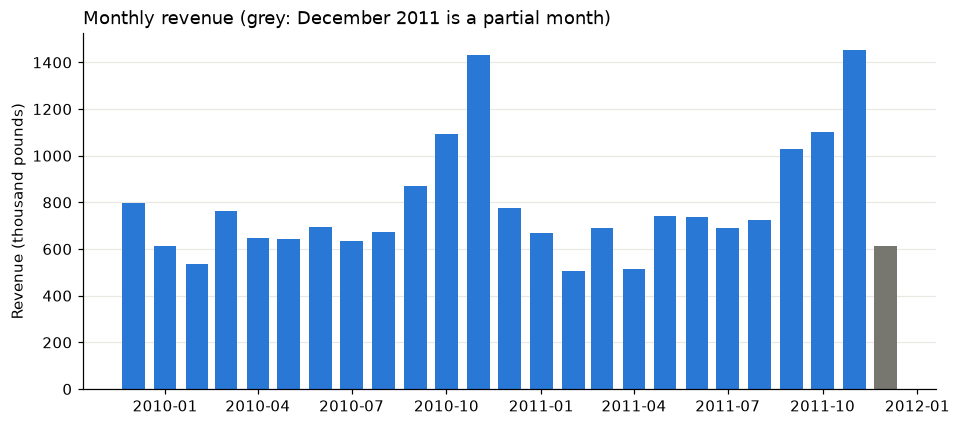

Revenue Dec 2009 to Nov 2010: £9,395,855
Revenue Dec 2010 to Nov 2011: £9,632,333  (+2.5% year on year)
Share of revenue earned in September to November: 36.7%


In [4]:
monthly = sales.groupby("Month").agg(revenue=("Revenue", "sum"), orders=("Invoice", "nunique"))
complete = monthly.iloc[:-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(complete.index, complete["revenue"] / 1000, width=22, color=BLUE)
ax.bar(monthly.index[-1:], monthly["revenue"].iloc[-1:] / 1000, width=22, color=GREY)
ax.set_ylabel("Revenue (thousand pounds)")
ax.set_title("Monthly revenue (grey: December 2011 is a partial month)", loc="left")
ax.grid(axis="x", visible=False)
plt.show()

year1 = monthly.loc["2009-12":"2010-11", "revenue"].sum()
year2 = monthly.loc["2010-12":"2011-11", "revenue"].sum()
peak_share = monthly.loc[monthly.index.month.isin([9, 10, 11]), "revenue"].sum() / complete["revenue"].sum()
print(f"Revenue Dec 2009 to Nov 2010: £{year1:,.0f}")
print(f"Revenue Dec 2010 to Nov 2011: £{year2:,.0f}  ({year2 / year1 - 1:+.1%} year on year)")
print(f"Share of revenue earned in September to November: {peak_share:.1%}")

Sales are strongly seasonal. Revenue builds from September and peaks in November as trade customers stock up for Christmas, then drops in December and January. Any model evaluated on this data has to respect that: customers are much more likely to order in the autumn than in the spring.

### Geography and revenue concentration

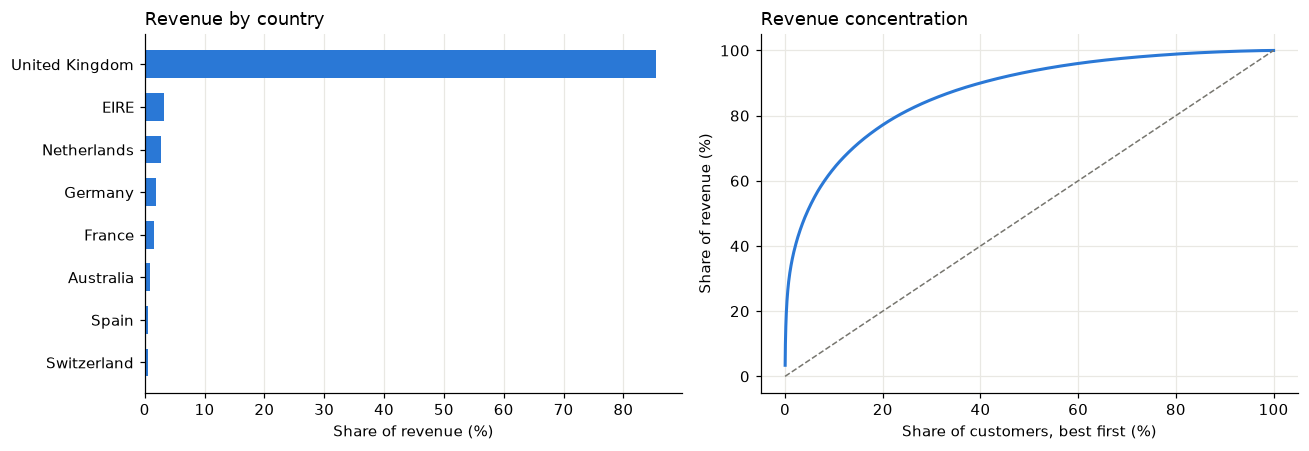

5,852 identified customers
Top 1% of customers: 31.9% of revenue.  Top 20%: 77.2% of revenue.
United Kingdom share of revenue: 85.5%


In [5]:
by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
country_share = (by_country / by_country.sum()).head(8)

customer_revenue = cust.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
cumulative = customer_revenue.cumsum() / customer_revenue.sum()
customer_share = np.arange(1, len(cumulative) + 1) / len(cumulative)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(country_share.index[::-1], country_share.values[::-1] * 100, color=BLUE, height=0.65)
axes[0].set_xlabel("Share of revenue (%)")
axes[0].set_title("Revenue by country", loc="left")
axes[0].grid(axis="y", visible=False)
axes[1].plot(customer_share * 100, cumulative.values * 100, color=BLUE, lw=2)
axes[1].plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
axes[1].set(xlabel="Share of customers, best first (%)", ylabel="Share of revenue (%)")
axes[1].set_title("Revenue concentration", loc="left")
plt.tight_layout()
plt.show()

top20 = float(cumulative.iloc[int(len(cumulative) * 0.2) - 1])
top1 = float(cumulative.iloc[int(len(cumulative) * 0.01) - 1])
print(f"{len(customer_revenue):,} identified customers")
print(f"Top 1% of customers: {top1:.1%} of revenue.  Top 20%: {top20:.1%} of revenue.")
print(f"United Kingdom share of revenue: {country_share.iloc[0]:.1%}")

The business is overwhelmingly domestic, and revenue is highly concentrated: a fifth of customers produce roughly three quarters of the revenue, and the top one percent alone produce nearly a third. Losing a handful of top accounts would hurt more than losing hundreds of small ones, which is the case for treating customers differently.

## 5. Retention: cohort analysis

Customers are grouped by the month of their first purchase (their cohort). For each cohort, the table shows the share who bought again in each later month. This separates two things that a raw sales chart mixes together: acquiring new customers and keeping existing ones.

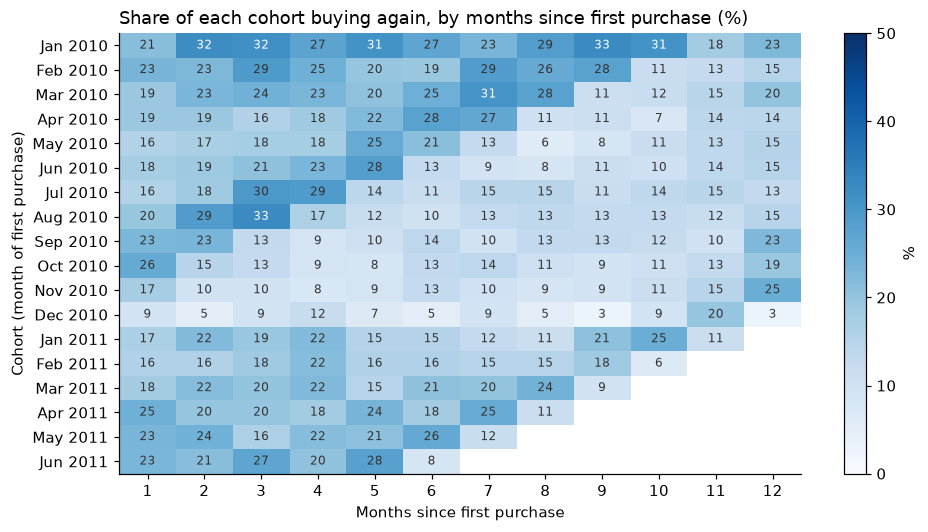

Average share buying again one month after first purchase: 19.4%
Average share active in month 6: 16.8%;  in month 12: 16.7%
Customers with exactly one order in two years: 27.6%


In [6]:
first_month = cust.groupby("CustomerID")["Month"].min().rename("Cohort")
activity = cust[["CustomerID", "Month"]].drop_duplicates().join(first_month, on="CustomerID")
activity["Age"] = (activity["Month"].dt.year - activity["Cohort"].dt.year) * 12 + (activity["Month"].dt.month - activity["Cohort"].dt.month)
cohort_counts = activity.pivot_table(index="Cohort", columns="Age", values="CustomerID", aggfunc="nunique")
retention = cohort_counts.div(cohort_counts[0], axis=0)
retention = retention.loc["2010-01":"2011-06", 1:12]

fig, ax = plt.subplots(figsize=(10, 5.2))
image = ax.imshow(retention.values * 100, cmap="Blues", aspect="auto", vmin=0, vmax=50)
ax.set_xticks(range(retention.shape[1]), retention.columns)
ax.set_yticks(range(retention.shape[0]), [c.strftime("%b %Y") for c in retention.index])
ax.set(xlabel="Months since first purchase", ylabel="Cohort (month of first purchase)")
ax.set_title("Share of each cohort buying again, by months since first purchase (%)", loc="left")
ax.grid(False)
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        value = retention.values[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value * 100:.0f}", ha="center", va="center", fontsize=8, color="white" if value > 0.3 else "#333")
fig.colorbar(image, ax=ax, label="%")
plt.show()

print(f"Average share buying again one month after first purchase: {retention[1].mean():.1%}")
print(f"Average share active in month 6: {retention[6].mean():.1%};  in month 12: {retention[12].mean():.1%}")
one_time = (cust.groupby('CustomerID')['Invoice'].nunique() == 1).mean()
print(f"Customers with exactly one order in two years: {one_time:.1%}")

In any given later month, a little under a fifth of a cohort comes back to buy, and that share is fairly stable from month to month instead of decaying to zero. So there is a loyal core that keeps ordering. At the same time, more than a quarter of customers order once and never return. Those two groups need different treatment, which is what segmentation is for.

## 6. Customer segmentation

The classic way to summarise a customer is **RFM**:

* **Recency**: days since the last order
* **Frequency**: number of orders
* **Monetary**: total spend

All three are heavily skewed (a few customers have hundreds of orders), so they are log-transformed and standardised before clustering. Otherwise the clusters would only reflect the extreme accounts.

In [7]:
snapshot = cust["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = cust.groupby("CustomerID").agg(
    recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"),
)
rfm_scaler = StandardScaler()
rfm_scaled = rfm_scaler.fit_transform(np.log1p(rfm))
rfm.describe().T[["mean", "50%", "max"]].round(1)

,mean,50%,max
recency,200.2,95.0,739.0
frequency,6.3,3.0,373.0
monetary,2916.7,856.0,580987.0


### How many segments?

The silhouette score measures how well separated the clusters are (higher is better). It is computed for two to eight clusters.

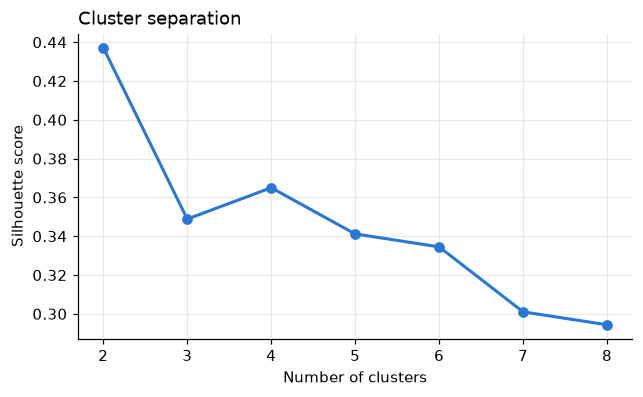

{2: 0.437, 3: 0.349, 4: 0.365, 5: 0.341, 6: 0.335, 7: 0.301, 8: 0.294}


In [8]:
sil = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(rfm_scaled)
    sil[k] = silhouette_score(rfm_scaled, labels, sample_size=5000, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(list(sil), list(sil.values()), "o-", color=BLUE, lw=2)
ax.set(xlabel="Number of clusters", ylabel="Silhouette score")
ax.set_title("Cluster separation", loc="left")
plt.show()
print({k: round(v, 3) for k, v in sil.items()})

Two clusters score highest, but a split into "good" and "poor" customers tells a marketing team nothing it does not already know. The score declines only gradually as clusters are added, so **four segments** are used: enough to separate distinct behaviours, few enough that each can get its own campaign.

In [9]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(rfm_scaled)
rfm["cluster"] = kmeans.labels_
centres = pd.DataFrame(kmeans.cluster_centers_, columns=["recency", "frequency", "monetary"])
value_score = centres["frequency"] + centres["monetary"] - centres["recency"]
best, worst = value_score.idxmax(), value_score.idxmin()
middle = centres.drop(index=[best, worst])["recency"]
cluster_names = {best: "Champions", middle.idxmin(): "New and promising", middle.idxmax(): "At risk", worst: "Lapsed"}
ORDER = ["Champions", "New and promising", "At risk", "Lapsed"]
rfm["segment"] = rfm["cluster"].map(cluster_names)

profile = rfm.groupby("segment").agg(customers=("recency", "size"), median_recency_days=("recency", "median"),
                                     median_orders=("frequency", "median"), median_spend=("monetary", "median"), revenue=("monetary", "sum"))
profile["share_of_customers"] = profile["customers"] / profile["customers"].sum()
profile["share_of_revenue"] = profile["revenue"] / profile["revenue"].sum()
profile = profile.loc[ORDER]
profile.round(2)

,customers,median_recency_days,median_orders,median_spend,revenue,share_of_customers,share_of_revenue
segment,,,,,,,
Champions,1182,16.0,13.0,4904.98,12517347.03,0.20,0.73
New and promising,1246,24.0,3.0,720.36,1048418.89,0.21,0.06
At risk,1455,184.0,4.0,1455.27,2878425.82,0.25,0.17
Lapsed,1969,401.0,1.0,275.88,624376.23,0.34,0.04


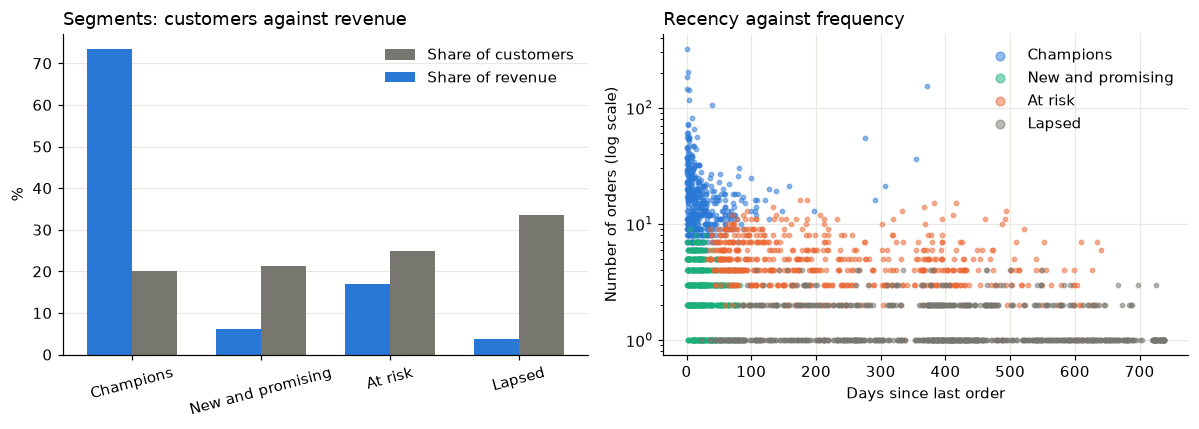

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(profile.index, profile["share_of_customers"] * 100, color=GREY, width=0.35, align="edge", label="Share of customers")
axes[0].bar(profile.index, profile["share_of_revenue"] * 100, color=BLUE, width=-0.35, align="edge", label="Share of revenue")
axes[0].set_ylabel("%")
axes[0].set_title("Segments: customers against revenue", loc="left")
axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)
axes[0].tick_params(axis="x", rotation=15)
sample = rfm.sample(2500, random_state=SEED)
for name, color in zip(profile.index, [BLUE, AQUA, ORANGE, GREY]):
    part = sample[sample["segment"] == name]
    axes[1].scatter(part["recency"], part["frequency"], s=8, alpha=0.5, color=color, label=name)
axes[1].set_yscale("log")
axes[1].set(xlabel="Days since last order", ylabel="Number of orders (log scale)")
axes[1].set_title("Recency against frequency", loc="left")
axes[1].legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.show()

**What each segment needs**

| Segment | Who they are | Action |
|---|---|---|
| Champions | Ordered in the last few weeks, order often, spend the most. A fifth of customers and nearly three quarters of revenue | Protect: account management, early access, no discounts needed |
| New and promising | Ordered in the last few weeks but only a few times, at low value so far | Convert: a well-timed follow-up offer to build the habit |
| At risk | Used to order regularly at good value, but have not ordered for about six months | Win back now, while they still remember the brand. This is where retention money pays |
| Lapsed | A single small order more than a year ago | Low-cost reactivation only, or let go |

The names are assigned by rule from the cluster centres: the cluster with the best combined score is Champions, the worst is Lapsed, and of the two in between, the one with more recent orders is New and promising and the other is At risk. The profile table above confirms each name matches its numbers.

## 7. Predicting repeat purchase

Segments describe the past. The next step is to predict the future: **will this customer place an order in the next 90 days?**

### Setting up the problem without leaking the future

Pick a cutoff date. Features describe each customer using only the 365 days **before** the cutoff. The label says whether they ordered in the 90 days **after** it.

* **Training** uses three cutoffs: 1 December 2010, 1 March 2011 and 1 June 2011.
* **Testing** uses a later cutoff, 1 September 2011, whose 90-day outcome window no training example overlaps.

This is out-of-time validation. It mimics how the model would be used: trained on the past, applied to the future. It is a tougher and more honest test than a random split, because the test period is the autumn peak, when customers behave differently from the periods the model learned from.

In [11]:
orders = cust.groupby(["CustomerID", "Invoice"]).agg(date=("InvoiceDate", "min"), revenue=("Revenue", "sum"), products=("StockCode", "nunique")).reset_index()
uk_customers = set(cust.loc[cust["Country"] == "United Kingdom", "CustomerID"])
returns = cancellations.dropna(subset=["Customer ID" if "Customer ID" in cancellations else "CustomerID"]).copy()
returns["CustomerID"] = returns["CustomerID"].astype(int)
return_events = returns.groupby(["CustomerID", "Invoice"])["InvoiceDate"].min().reset_index()

FEATURES = ["recency", "frequency", "monetary", "avg_order_value", "tenure", "days_between_orders",
            "orders_90d", "spend_90d", "products_per_order", "returns", "uk"]


def snapshot_features(cutoff, history_days=365, horizon_days=90):
    cutoff = pd.Timestamp(cutoff)
    window = orders[(orders["date"] < cutoff) & (orders["date"] >= cutoff - pd.Timedelta(days=history_days))]
    recent = window[window["date"] >= cutoff - pd.Timedelta(days=90)]
    f = window.groupby("CustomerID").agg(
        recency=("date", lambda s: (cutoff - s.max()).days),
        tenure=("date", lambda s: (cutoff - s.min()).days),
        frequency=("Invoice", "nunique"),
        monetary=("revenue", "sum"),
        products_per_order=("products", "mean"),
    )
    f["avg_order_value"] = f["monetary"] / f["frequency"]
    f["days_between_orders"] = np.where(f["frequency"] > 1, (f["tenure"] - f["recency"]) / (f["frequency"] - 1).clip(lower=1), np.nan)
    f["orders_90d"] = recent.groupby("CustomerID")["Invoice"].nunique().reindex(f.index).fillna(0)
    f["spend_90d"] = recent.groupby("CustomerID")["revenue"].sum().reindex(f.index).fillna(0)
    past_returns = return_events[(return_events["InvoiceDate"] < cutoff) & (return_events["InvoiceDate"] >= cutoff - pd.Timedelta(days=history_days))]
    f["returns"] = past_returns.groupby("CustomerID")["Invoice"].nunique().reindex(f.index).fillna(0)
    f["uk"] = f.index.isin(uk_customers).astype(int)
    future = orders[(orders["date"] >= cutoff) & (orders["date"] < cutoff + pd.Timedelta(days=horizon_days))]
    f["bought"] = f.index.isin(future["CustomerID"]).astype(int)
    f["future_revenue"] = future.groupby("CustomerID")["revenue"].sum().reindex(f.index).fillna(0)
    f["cutoff"] = cutoff
    return f


train = pd.concat([snapshot_features(c) for c in ["2010-12-01", "2011-03-01", "2011-06-01"]])
test = snapshot_features("2011-09-01")
for name, part in [("train", train), ("test", test)]:
    print(f"{name:<6}{len(part):>7,} customer snapshots   bought again within 90 days: {part['bought'].mean():.1%}")
print(train.groupby("cutoff")["bought"].mean().round(3).to_string())

train  12,823 customer snapshots   bought again within 90 days: 35.6%
test    4,324 customer snapshots   bought again within 90 days: 49.5%
cutoff
2010-12-01    0.332
2011-03-01    0.369
2011-06-01    0.366


The repeat purchase rate is higher in the test period than in training, as expected for the autumn peak. A model can still rank customers correctly in that situation, but its probabilities will tend to run low. Both are checked below.

### Models

* **Rule of thumb**: score customers by recency alone. This is what a marketer without a model would do.
* **Logistic regression** on all features (log-transformed).
* **Gradient boosted trees**, which can use interactions such as "ordered often **and** is overdue relative to their usual gap".

In [12]:
X_train, y_train = train[FEATURES], train["bought"]
X_test, y_test = test[FEATURES], test["bought"]

LOG_COLUMNS = ["recency", "frequency", "monetary", "avg_order_value", "tenure", "days_between_orders", "orders_90d", "spend_90d", "products_per_order", "returns"]


def log_frame(frame):
    out = frame.copy()
    out["days_between_orders"] = out["days_between_orders"].fillna(365)
    out[LOG_COLUMNS] = np.log1p(out[LOG_COLUMNS])
    return out


logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(log_frame(X_train), y_train)

earlier = train["cutoff"] < pd.Timestamp("2011-06-01")
gbm = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=3, min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
                        reg_lambda=5.0, eval_metric="logloss", early_stopping_rounds=50, random_state=SEED, n_jobs=4)
gbm.fit(X_train[earlier], y_train[earlier], eval_set=[(X_train[~earlier], y_train[~earlier])], verbose=False)
n_trees = gbm.best_iteration + 1
gbm = xgb.XGBClassifier(n_estimators=n_trees, learning_rate=0.03, max_depth=3, min_child_weight=20, subsample=0.8, colsample_bytree=0.8,
                        reg_lambda=5.0, random_state=SEED, n_jobs=4).fit(X_train, y_train)
print("Trees:", n_trees, "(chosen by early stopping on the June 2011 cutoff, then refitted on all three training cutoffs)")

p_recency = -X_test["recency"].values
p_logit = logit.predict_proba(log_frame(X_test))[:, 1]
p_gbm = gbm.predict_proba(X_test)[:, 1]

rows = []
for name, p in [("Recency only", p_recency), ("Logistic regression", p_logit), ("Gradient boosting", p_gbm)]:
    rows.append({"model": name, "AUROC": roc_auc_score(y_test, p), "Average precision": average_precision_score(y_test, p),
                 "Brier score": np.nan if name == "Recency only" else brier_score_loss(y_test, p)})
metrics = pd.DataFrame(rows).set_index("model")
print(f"Test base rate: {y_test.mean():.3f}")
metrics.round(4)

Trees: 205 (chosen by early stopping on the June 2011 cutoff, then refitted on all three training cutoffs)
Test base rate: 0.495


,AUROC,Average precision,Brier score
model,,,
Recency only,0.7080,0.6802,NaN
Logistic regression,0.7686,0.7858,0.2205
Gradient boosting,0.7725,0.7940,0.2169


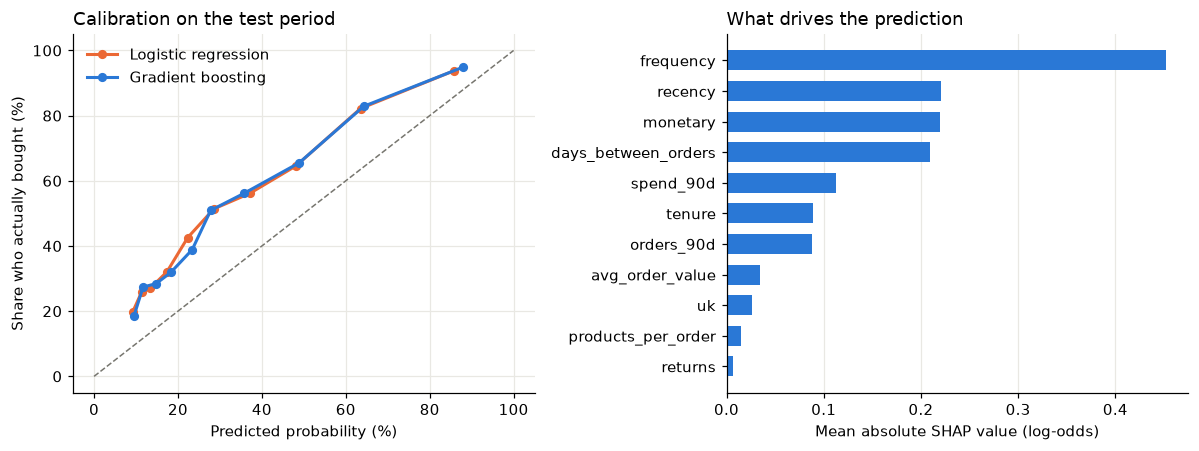

Mean predicted probability 0.342 against actual rate 0.495


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, color in [("Logistic regression", p_logit, ORANGE), ("Gradient boosting", p_gbm, BLUE)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred * 100, frac * 100, "o-", color=color, lw=2, ms=5, label=name)
axes[0].plot([0, 100], [0, 100], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="Predicted probability (%)", ylabel="Share who actually bought (%)")
axes[0].set_title("Calibration on the test period", loc="left")
axes[0].legend(frameon=False)

contrib = gbm.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()
axes[1].barh(importance.index, importance.values, color=BLUE, height=0.65)
axes[1].set_xlabel("Mean absolute SHAP value (log-odds)")
axes[1].set_title("What drives the prediction", loc="left")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Mean predicted probability {p_gbm.mean():.3f} against actual rate {y_test.mean():.3f}")

**Reading the results**

* Both models rank customers clearly better than recency alone (AUROC 0.77 against 0.71), so frequency, spend and ordering rhythm add real information beyond "when did they last buy".
* Logistic regression and gradient boosting are close. With eleven well-chosen features there is limited room for a more flexible model to add much.
* The calibration plot shows the effect of seasonality: points sit above the diagonal, meaning more customers bought than the model predicted, because the test window is the autumn peak. The **ranking** is what matters for deciding whom to contact, and it holds. If the probabilities themselves were needed, for example for a revenue forecast, the model should be recalibrated for the season.

## 8. Using the model: who to contact

Suppose the marketing team can only contact a share of customers. Rank customers by predicted probability and see how many of the actual buyers, and how much of the actual revenue, fall in the top of the list.

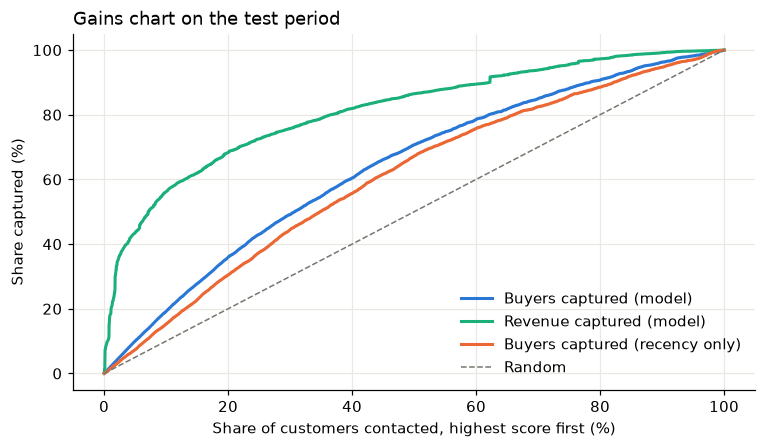

Top 10% by model score: 19% of buyers, 56% of revenue   (recency only: 15% of buyers)
Top 20% by model score: 36% of buyers, 68% of revenue   (recency only: 30% of buyers)
Top 30% by model score: 49% of buyers, 76% of revenue   (recency only: 44% of buyers)
Top 50% by model score: 71% of buyers, 87% of revenue   (recency only: 67% of buyers)
Purchase rate in the top tenth: 95%.  In the bottom half: 29%.


In [14]:
ranked = test.assign(p=p_gbm).sort_values("p", ascending=False)
ranked["share_contacted"] = np.arange(1, len(ranked) + 1) / len(ranked)
ranked["buyers_captured"] = ranked["bought"].cumsum() / ranked["bought"].sum()
ranked["revenue_captured"] = ranked["future_revenue"].cumsum() / ranked["future_revenue"].sum()
by_recency = test.sort_values("recency")
recency_captured = by_recency["bought"].cumsum().values / by_recency["bought"].sum()

fig, ax = plt.subplots()
ax.plot(ranked["share_contacted"] * 100, ranked["buyers_captured"] * 100, color=BLUE, lw=2, label="Buyers captured (model)")
ax.plot(ranked["share_contacted"] * 100, ranked["revenue_captured"] * 100, color=AQUA, lw=2, label="Revenue captured (model)")
ax.plot(ranked["share_contacted"] * 100, recency_captured * 100, color=ORANGE, lw=2, label="Buyers captured (recency only)")
ax.plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="Random")
ax.set(xlabel="Share of customers contacted, highest score first (%)", ylabel="Share captured (%)")
ax.set_title("Gains chart on the test period", loc="left")
ax.legend(frameon=False)
plt.show()

gains = {}
for share in [0.1, 0.2, 0.3, 0.5]:
    row = ranked.iloc[int(len(ranked) * share) - 1]
    gains[share] = (row["buyers_captured"], row["revenue_captured"], recency_captured[int(len(ranked) * share) - 1])
    print(f"Top {share:.0%} by model score: {row['buyers_captured']:.0%} of buyers, {row['revenue_captured']:.0%} of revenue   (recency only: {gains[share][2]:.0%} of buyers)")
top_decile_rate = ranked.iloc[: len(ranked) // 10]["bought"].mean()
bottom_half_rate = ranked.iloc[len(ranked) // 2:]["bought"].mean()
print(f"Purchase rate in the top tenth: {top_decile_rate:.0%}.  In the bottom half: {bottom_half_rate:.0%}.")

Almost every customer in the model's top tenth went on to buy, against fewer than a third in the bottom half. Because the customers most likely to return are also the biggest spenders, the top fifth of the list accounts for about two thirds of the revenue in the following 90 days.

Two practical uses follow, and they point in opposite directions:

* **Do not waste budget on the top of the list.** Customers with a very high score will mostly buy anyway. A discount sent to them gives away margin.
* **Focus retention spend on valuable customers whose score has dropped.** A Champion whose probability is falling is the account worth a phone call.

Deciding which contacts actually change behaviour needs an experiment (a randomly held-out control group), which this historical data cannot provide.

## 9. Export for the live dashboard

In [15]:
def export_trees(model, columns, sample):
    booster = model.get_booster()
    index = {name: i for i, name in enumerate(columns)}
    trees = []
    for dump in booster.get_dump(dump_format="json"):
        nodes = {}
        stack = [json.loads(dump)]
        while stack:
            node = stack.pop()
            nodes[node["nodeid"]] = node
            stack.extend(node.get("children", []))
        size = max(nodes) + 1
        tree = {"f": [-1] * size, "t": [0] * size, "y": [0] * size, "n": [0] * size, "m": [0] * size, "v": [0] * size}
        for i, node in nodes.items():
            if "leaf" in node:
                tree["v"][i] = round(node["leaf"], 6)
            else:
                tree["f"][i] = index[node["split"]]
                tree["t"][i] = float(np.float32(node["split_condition"]))
                tree["y"][i], tree["n"][i], tree["m"][i] = node["yes"], node["no"], node["missing"]
        trees.append(tree)

    def raw_sum(row):
        total = 0.0
        for tree in trees:
            i = 0
            while tree["f"][i] != -1:
                value = row[tree["f"][i]]
                i = tree["m"][i] if np.isnan(value) else (tree["y"][i] if value < tree["t"][i] else tree["n"][i])
            total += tree["v"][i]
        return total

    values = sample.to_numpy(dtype=np.float32).astype(float)
    sums = np.array([raw_sum(row) for row in values])
    margins = booster.predict(xgb.DMatrix(sample), output_margin=True)
    base = float(np.mean(margins - sums))
    assert np.max(np.abs(sums + base - margins)) < 1e-4, "exported trees do not reproduce the model"
    return {"features": list(columns), "base": round(base, 6), "trees": trees, "objective": "logistic"}


exported = export_trees(gbm, FEATURES, X_test.head(500))
print("Exported", len(exported["trees"]), "trees. Predictions match XGBoost on 500 test customers.")

Exported 205 trees. Predictions match XGBoost on 500 test customers.


In [16]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records"))


frac, mean_pred = calibration_curve(y_test, p_gbm, n_bins=10, strategy="quantile")
points = np.linspace(0, len(ranked) - 1, 101).astype(int)
scatter = rfm.sample(1500, random_state=SEED)
summary = {
    "lines_raw": int(len(raw)), "lines_clean": int(len(sales)), "customers": int(len(rfm)),
    "revenue_total": float(sales["Revenue"].sum()), "orders_total": int(sales["Invoice"].nunique()),
    "date_from": raw["InvoiceDate"].min().strftime("%Y-%m-%d"), "date_to": raw["InvoiceDate"].max().strftime("%Y-%m-%d"),
    "cleaning": json.loads(audit.to_json(orient="records")),
    "monthly": [{"month": m.strftime("%Y-%m"), "revenue": float(r["revenue"]), "orders": int(r["orders"])} for m, r in monthly.iterrows()],
    "yoy": float(year2 / year1 - 1), "peak_share": float(peak_share),
    "country_share": [{"country": c, "share": float(v)} for c, v in country_share.items()],
    "concentration": {"customers": (customer_share[points[:101] * 0 + np.linspace(0, len(cumulative) - 1, 101).astype(int)]).tolist(),
                      "revenue": cumulative.values[np.linspace(0, len(cumulative) - 1, 101).astype(int)].tolist(), "top20": top20, "top1": top1},
    "retention": {"cohorts": [c.strftime("%b %Y") for c in retention.index], "ages": [int(a) for a in retention.columns],
                  "values": [[None if np.isnan(v) else round(float(v), 4) for v in row] for row in retention.values]},
    "one_time_share": float(one_time),
    "segments": records(profile),
    "segment_model": {"mean": rfm_scaler.mean_.tolist(), "scale": rfm_scaler.scale_.tolist(),
                      "centres": kmeans.cluster_centers_.tolist(), "names": [cluster_names[i] for i in range(K)]},
    "segment_scatter": [{"segment": r["segment"], "recency": int(r["recency"]), "frequency": int(r["frequency"])} for _, r in scatter.iterrows()],
    "silhouette": {str(k): float(v) for k, v in sil.items()},
    "metrics": json.loads(metrics.reset_index().to_json(orient="records")),
    "base_rate_test": float(y_test.mean()), "test_customers": int(len(test)),
    "calibration": {"predicted": mean_pred.tolist(), "observed": frac.tolist()},
    "importance": [{"feature": k, "value": float(v)} for k, v in importance.sort_values(ascending=False).items()],
    "gains": {"contacted": ranked["share_contacted"].values[points].tolist(), "buyers": ranked["buyers_captured"].values[points].tolist(),
              "revenue": ranked["revenue_captured"].values[points].tolist(), "recency": recency_captured[points].tolist()},
    "score_quantiles": np.quantile(p_gbm, np.linspace(0, 1, 101)).tolist(),
    "medians": {c: float(X_test[c].median()) for c in FEATURES},
}
(APP / "model.json").write_text(json.dumps(exported, separators=(",", ":")))
(APP / "summary.json").write_text(json.dumps(summary, separators=(",", ":")))
print("model.json", round((APP / "model.json").stat().st_size / 1024), "KB; summary.json", round((APP / "summary.json").stat().st_size / 1024), "KB")

model.json 63 KB; summary.json 97 KB


## 10. Conclusions

* Revenue is seasonal, peaking each autumn, and highly concentrated in a small group of customers.
* Cohort analysis shows a stable loyal core alongside a large group who order once and never return.
* Four behavioural segments separate the Champions, who produce most of the revenue, from new customers worth converting, once-active customers at risk of leaving, and those already lapsed. Each maps to a different marketing action.
* A model using eleven features from the previous 12 months ranks customers by likelihood of ordering in the next 90 days better than recency alone (AUROC 0.77 against 0.71), on a later period it was not trained on. The top fifth of the ranked list holds over a third of the buyers and about two thirds of the following 90 days' revenue.

**Limitations**

* One retailer, two years. Many customers are wholesalers, so behaviour differs from a consumer business.
* The test period is the seasonal peak, so predicted probabilities run low even though the ranking holds. Recalibration by season would fix this.
* About a fifth of lines have no customer ID and are excluded from customer analysis.
* Predicting who will buy is not the same as knowing whom a campaign will persuade. That needs a randomised test and an uplift model.

**Next steps.** Predict 90-day spend as well as purchase probability to get expected customer value, recalibrate by season, and design a holdout experiment to measure the true effect of a retention campaign.